# Notebook 13 — Multimodel patent clustering benchmark (K-Means)

**Project:** CNR–ISTAT · 63,968 publications · 32 WIPO technological fields  
**Role:** Mauro generated patent embeddings; Brian performs clustering and validation.  
**Input:** Notebook 12's aligned master index + eight Hugging Face `.npy` matrices. Optionally, the **chunked MiniLM** baseline from Notebook 09.

**Research questions**

1. Holding the patents and K-Means procedure fixed, how do the **embedding models** change the clustering?
2. Are groups well separated (*cosine silhouette*), associated with the **WIPO reference** (*AMI*), and stable across different initializations (*ARI*)?
3. How do patents distribute among clusters, and do the groups show patent-office effects?

**Crucial:** WIPO is a useful external comparison, **not** human semantic ground truth. More WIPO agreement does not automatically imply better technological discovery. Also, raw silhouette values across different embedding geometries are descriptive rather than definitive model rankings.

**First run:** 200 patents per WIPO field (6,400 total), **K=8 and K=16**, 3 seeds. Once it finishes, optionally extend to five seeds (existing checkpoints are reused) and then run a separate full-corpus experiment. No embedding generation or GPU is required; a CPU/High-RAM Colab runtime is suitable.

## 0. Installation and Drive

Use a fresh Google Colab notebook. Mount the **same Google Drive** used in Notebook 12. All result tables, labels, fitted models, and figures will be written to Drive.

In [ ]:
# Lightweight dependencies. Colab normally supplies NumPy, pandas, and scikit-learn.
%pip -q install "huggingface_hub>=0.25" "pyarrow>=15" "scikit-learn>=1.4" joblib matplotlib seaborn threadpoolctl tabulate

In [ ]:
# Tools: arrays, tables, plots, clustering, reproducibility, Hugging Face files.
import os, gc, json, time, hashlib, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from huggingface_hub import hf_hub_download
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_mutual_info_score, adjusted_rand_score,
                             silhouette_score, pairwise_distances)
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

# 'drive' exists in Google Colab; outside Colab use the current directory.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/istat_patents')
except ImportError:
    ROOT = Path.cwd() / 'istat_patents'

AUDIT_DIR = ROOT / 'semantic_results_v9_multimodel_audit'   # Notebook 12
MINILM_DIR = ROOT / 'semantic_results_v6_full_corpus'      # Notebook 09
RESULTS_ROOT = ROOT / 'semantic_results_v10_multimodel_kmeans'
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
print('Notebook 12:', AUDIT_DIR)
print('Notebook 13 outputs:', RESULTS_ROOT)

Mounted at /content/drive
Notebook 12: /content/drive/MyDrive/istat_patents/semantic_results_v9_multimodel_audit
Notebook 13 outputs: /content/drive/MyDrive/istat_patents/semantic_results_v10_multimodel_kmeans


## 1. Experiment settings — edit here

- **Default:** all eight HF models; a **6,400-patent pilot**; `K=[8,16]`; three seeds with ten initializations per seed.
- `RUN_FULL_CORPUS=True` switches to all 63,968 patents. Start with the pilot.
- `SEEDS=[42,43,44,45,46]` makes the repeated-seed benchmark more thorough, but adds runtime.
- **Always keep one common patent cohort** across all models and the old MiniLM baseline.
- `EXCLUDE_PLACEHOLDERS` defines a *separate* experiment, not an arbitrary per-model exclusion.
- The two token-processing pipelines are **not equivalent**: Mauro used no chunking; MiniLM 09 used overlap + averaged chunks. We will label this clearly.

In [ ]:
# Version-pinned Hugging Face dataset (reported in Notebook 12).
HF_REPO = 'istat-ai/wipo32-patent-embeddings'
HF_REVISION = 'e570ab0121c6dff0e61b05b64dd7ee21b98b78b7'

# The folder names are the actual Hugging Face paths; all 8 are enabled.
MODEL_FOLDERS = [
    'bge-m3', 'qwen3-embedding-4b', 'qwen3-embedding-0.6b',
    'embeddinggemma-300m', 'paecter', 'pat-specter',
    'sbert-adapt-ub', 'mpnet',
]

# Include previously computed, chunk-averaged MiniLM if Notebook 09's files exist.
INCLUDE_MINILM09 = True

# FEASIBLE FIRST RUN: 32 WIPO fields x 200 patents = 6,400 patents.
RUN_FULL_CORPUS = True #False done already
PER_WIPO_FIELD = 200
EXCLUDE_PLACEHOLDERS = False

# Identical K-Means parameters for every embedding representation.
K_VALUES = [8, 16]
SEEDS = [42, 43, 44]             # Later extend to [42, 43, 44, 45, 46].
N_INIT = 10                       # Ten starts per random seed.
MAX_ITER = 300
THREADS = 4                     # Often faster and more predictable in Colab.

# Use one identical 1,200-patent evaluation cohort across all models and K/seeds.
SILHOUETTE_SAMPLE_N = 1200
PILOT_SEED = 20261116
SILHOUETTE_SEED = 42

# Download HF arrays to Colab's cache for speed, save fitted results to Drive.
# Change this to a Drive path if you want persistent HF downloads across sessions.
HF_CACHE_DIR = '/content/hf_patent_cache'

# Export patents for manual review (near centroid, peripheral, ambiguous).
REVIEW_PER_TYPE_PER_CLUSTER = 5
PRINT_PROGRESS = True

MODE = 'full' if RUN_FULL_CORPUS else f'pilot_{PER_WIPO_FIELD}_per_field'
POPULATION = 'excluding_placeholders' if EXCLUDE_PLACEHOLDERS else 'all_texts'
OUT_DIR = RESULTS_ROOT / MODE / POPULATION
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / 'models').mkdir(exist_ok=True)
(OUT_DIR / 'labels').mkdir(exist_ok=True)
(OUT_DIR / 'figures').mkdir(exist_ok=True)
print('Current experiment:', OUT_DIR)

Current experiment: /content/drive/MyDrive/istat_patents/semantic_results_v10_multimodel_kmeans/full/all_texts


## 2. Load Notebook 12's common patent index and verify alignment

Notebook 12 established that **all eight `ids.parquet` files have the same row order**. Nevertheless, every matrix will be checked against the canonical ordered patent identifiers before fitting.

The WIPO label here follows Notebook 09's *one-field-per-publication convention* (first matching WIPO field), since some patents have multiple applicable fields. This is a **measurement convention**, not a claim that patents have only one technology.

In [ ]:
# Both files were exported by Notebook 12.
MASTER_FILE = AUDIT_DIR / '12_patents_master_index.parquet'
MANIFEST_FILE = AUDIT_DIR / '12_embedding_manifest.json'
INVENTORY_FILE = AUDIT_DIR / '12_model_inventory.csv'
for p in (MASTER_FILE, MANIFEST_FILE, INVENTORY_FILE):
    if not p.exists():
        raise FileNotFoundError(f'Missing {p}. Run Notebook 12 or copy its outputs to Drive.')

master = pd.read_parquet(MASTER_FILE)
manifest = json.loads(MANIFEST_FILE.read_text(encoding='utf-8'))
inventory = pd.read_csv(INVENTORY_FILE)

# Convert IDs to strings, not numbers: preserves leading zeros and fixed format.
master['publication_number'] = master['publication_number'].astype('string')
expected_n = int(manifest['n_publications'])
if len(master) != expected_n or not master['publication_number'].is_unique:
    raise ValueError('Master has unexpected row count or duplicate publication IDs.')
if master['publication_number'].isna().any():
    raise ValueError('Publication IDs contain missing values.')
if not {'wipo_field_number', 'office', 'abstract_is_placeholder'}.issubset(master.columns):
    raise ValueError('Notebook 12 master lacks WIPO / office / placeholder metadata.')
if manifest['dataset_revision'] != HF_REVISION:
    raise ValueError('Notebook 12 audit and this notebook refer to different HF commits.')
if not (manifest['all_model_id_orders_match'] and manifest['all_model_id_sets_match']):
    raise ValueError('Notebook 12 did not confirm identical model ID ordering.')

# Check exact ID order using the same null-delimited SHA-256 convention as Notebook 12.
def fingerprint(ids):
    h = hashlib.sha256()
    for item in ids:
        h.update(str(item).encode('utf-8'))
        h.update(b'\0')
    return h.hexdigest()

master_id_hash = fingerprint(master['publication_number'])
if master_id_hash != manifest['canonical_ids_order_sha256']:
    raise ValueError('Master publication row order differs from Notebook 12 manifest.')

# Consistent external reference categories for AMI.
master['wipo_field_number'] = pd.to_numeric(master['wipo_field_number'], errors='coerce')
if master['wipo_field_number'].isna().any():
    raise ValueError('Some patents lack the single-field WIPO reference.')
master['wipo_field_number'] = master['wipo_field_number'].astype(int)
if 'wipo_field_name' in master.columns:
    master['field_label'] = (master['wipo_field_number'].astype(str).str.zfill(2) + ' ' +
                             master['wipo_field_name'].fillna('Unknown').astype(str))
else:
    master['field_label'] = master['wipo_field_number'].astype(str).str.zfill(2)
master['office_group'] = master['office'].fillna('Unknown').astype(str).where(
    master['office'].fillna('Unknown').astype(str).isin(['CN','US','WO','EP','JP','KR']), 'Other')
master['abstract_is_placeholder'] = master['abstract_is_placeholder'].fillna(False).astype(bool)

print('Master shape:', master.shape)
print('WIPO fields:', master['wipo_field_number'].nunique())
print('Placeholder abstracts:', int(master['abstract_is_placeholder'].sum()))
print('Canonical ID hash:', master_id_hash[:20])
display(master[['publication_number','wipo_field_number','office','abstract_is_placeholder']].head())

Master shape: (63968, 11)
WIPO fields: 32
Placeholder abstracts: 3
Canonical ID hash: b828eb4827f13e90f197


,publication_number,wipo_field_number,office,abstract_is_placeholder
0,AU-2014369850-B2,16,AU,False
1,AU-2015305303-B2,27,AU,False
2,AU-2015306692-B2,11,AU,False
3,AU-2015322543-B2,15,AU,False
4,AU-2015366213-B2,15,AU,False


## 3. Freeze a single patent cohort for every model

Pilot selection is stratified by the **same deterministic one-field WIPO reference**. It chooses 200 patents per field using a fixed random seed. This may not perfectly recover the old pilot IDs; therefore, the original MiniLM vectors are **re-evaluated on this exact new pilot** rather than copying their previously published full-corpus metrics.

We also freeze one set of 1,200 evaluation indices for silhouette, avoiding different evaluation patents across models or initializations.

In [ ]:
# Construct the eligible pool using the exact same rule for every model.
eligible = master.loc[~master['abstract_is_placeholder']].copy() if EXCLUDE_PLACEHOLDERS else master.copy()

if RUN_FULL_CORPUS:
    cohort = eligible.copy()
else:
    # Pandas groupby.sample with a fixed seed gives a reproducible WIPO-balanced pilot.
    counts = eligible.groupby('wipo_field_number').size()
    if (counts < PER_WIPO_FIELD).any():
        raise ValueError('Some WIPO fields have too few patents: ' +
                         str(counts[counts < PER_WIPO_FIELD].to_dict()))
    cohort = (eligible.groupby('wipo_field_number', group_keys=False)
               .sample(n=PER_WIPO_FIELD, random_state=PILOT_SEED))

# Follow Notebook 12's canonical row order, making indexing into npy arrays safe.
cohort = cohort.sort_index().copy()
positions = cohort.index.to_numpy(dtype=np.int64)
cohort = cohort.reset_index(drop=True)
N = len(cohort)
assert cohort['publication_number'].is_unique
assert cohort['wipo_field_number'].nunique() == 32

# Fixed uniform sampling for silhouette. 1,200 x 1,200 cosine distances is manageable.
rng = np.random.RandomState(SILHOUETTE_SEED)
sil_pos = rng.permutation(N)[:min(SILHOUETTE_SAMPLE_N, N)]

# Fingerprint ensures that interrupted runs cannot mix different cohorts.
cohort_hash = fingerprint(cohort['publication_number'])
config = dict(repo=HF_REPO, revision=HF_REVISION, cohort_hash=cohort_hash,
              n_patents=N, models=MODEL_FOLDERS,
              include_minilm09=INCLUDE_MINILM09,
              full=RUN_FULL_CORPUS, per_field=PER_WIPO_FIELD,
              exclude_placeholders=EXCLUDE_PLACEHOLDERS,
              k_values=K_VALUES, seeds=SEEDS, n_init=N_INIT,
              max_iter=MAX_ITER, pilot_seed=PILOT_SEED,
              silhouette_n=len(sil_pos), silhouette_seed=SILHOUETTE_SEED)
config_path = OUT_DIR / 'experiment_config.json'
if config_path.exists():
    saved_config = json.loads(config_path.read_text(encoding='utf-8'))
    # Adding NEW seeds or NEW K values is safe: old model/label checkpoints are reused.
    # Changes to sample, model list, seed priority, n_init, or source data are NOT safe.
    previous_seeds = saved_config.get('seeds', [])
    previous_k = saved_config.get('k_values', [])
    immutable = [key for key in config if key not in ('seeds', 'k_values')]
    changed = [key for key in immutable if saved_config.get(key) != config[key]]
    extension_ok = (set(previous_seeds).issubset(SEEDS) and
                    set(previous_k).issubset(K_VALUES) and
                    bool(previous_seeds) and previous_seeds[0] == SEEDS[0])
    if changed or not extension_ok:
        raise RuntimeError('Experiment parameters differ from saved checkpoints: '
                           f'{changed}. Change output folder or restore original settings.')
    if saved_config != config:
        print('Safely extending previous experiment with additional seeds/K values.')
        config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
else:
    config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')

cohort.to_parquet(OUT_DIR / '13_cohort_master.parquet', index=False)
np.save(OUT_DIR / '13_master_positions.npy', positions)
np.save(OUT_DIR / '13_silhouette_sample_positions.npy', sil_pos)
print(f'Cohort: {N:,} patents | WIPO fields: {cohort.wipo_field_number.nunique()}')
print('ID checksum:', cohort_hash[:20])
print('Silhouette sample:', len(sil_pos))
display(cohort.groupby('wipo_field_number').size().rename('patents').to_frame().head())

Cohort: 63,968 patents | WIPO fields: 32
ID checksum: b828eb4827f13e90f197
Silhouette sample: 1200


,patents
wipo_field_number,
1,2000
2,2000
3,2000
4,1999
5,1999


## 4. Reusable loaders: download once, check IDs and vector quality

**One model at a time:** use `mmap_mode='r'` for the stored `float16` vectors, select only the cohort, convert to `float32`, check for invalid/zero rows, and L2-normalize again (float16 storage introduces tiny rounding errors).

The loader also rechecks model IDs against the master. **Do not join based only on row counts.**

In [ ]:
# Download each artifact from the exact pinned Hugging Face revision.
def get_file(folder, filename):
    return Path(hf_hub_download(repo_id=HF_REPO, repo_type='dataset',
                                revision=HF_REVISION, filename=f'{folder}/{filename}',
                                cache_dir=HF_CACHE_DIR))

# Model dimensions are retrieved from the audit inventory, not guessed from model names.
EXPECTED_DIM = dict(zip(inventory['folder'], inventory['embedding_dim'].astype(int)))

# Audit ordered IDs and load only the selected rows from the .npy matrix.
def load_hf_matrix(folder):
    ids = pd.read_parquet(get_file(folder, 'ids.parquet'))
    ids['publication_number'] = ids['publication_number'].astype('string')
    if len(ids) != len(master) or fingerprint(ids['publication_number']) != master_id_hash:
        raise ValueError(f'{folder}: ID order differs from the audited master.')
    if 'abstract_is_placeholder' in ids.columns:
        flags = ids['abstract_is_placeholder'].fillna(False).astype(bool).to_numpy()
        if not np.array_equal(flags, master['abstract_is_placeholder'].to_numpy()):
            raise ValueError(f'{folder}: placeholder flags differ from the audited master.')

    # Memory mapping avoids opening the entire float16 matrix in RAM before selection.
    raw = np.load(get_file(folder, 'embeddings.npy'), mmap_mode='r', allow_pickle=False)
    if raw.ndim != 2 or raw.shape != (len(master), EXPECTED_DIM[folder]):
        raise ValueError(f'{folder}: unexpected embedding shape {raw.shape}.')
    X = np.asarray(raw[positions], dtype=np.float32)
    del raw
    return check_and_normalize(X, folder)

# Shared numerical audit for BOTH Mauro's matrices and the original MiniLM baseline.
def check_and_normalize(X, model_name):
    if not np.isfinite(X).all():
        raise ValueError(f'{model_name}: NaN or infinite embedding values detected.')
    norm = np.linalg.norm(X, axis=1)
    if (norm < 1e-10).any():
        raise ValueError(f'{model_name}: zero-length embedding rows detected.')
    max_error = float(np.max(np.abs(norm - 1.0)))
    X = normalize(X, norm='l2', axis=1, copy=False)
    print(f'{model_name:25s}: X={X.shape}, float32, max L2 error before renormalization={max_error:.5f}')
    return np.ascontiguousarray(X, dtype=np.float32)

# Notebook 09 wrote its MiniLM matrix in sorted publication_number order.
# Align by its saved metadata, never by assuming the same position as HF.
def load_minilm09_matrix():
    embeddings_path = MINILM_DIR / 'full_minilm_chunked_embeddings.npy'
    metadata_path = MINILM_DIR / 'full_corpus_metadata.parquet'
    if not embeddings_path.exists() or not metadata_path.exists():
        raise FileNotFoundError('Notebook 09 baseline is unavailable: ' + str(embeddings_path))
    m = pd.read_parquet(metadata_path, columns=['publication_number'])
    source_ids = pd.Index(m['publication_number'].astype('string'))
    target_ids = pd.Index(cohort['publication_number'].astype('string'))
    if not source_ids.is_unique:
        raise ValueError('Notebook 09 metadata contains duplicate IDs.')
    indexer = source_ids.get_indexer(target_ids)
    if (indexer < 0).any():
        raise ValueError('Some sampled patents are missing from the old MiniLM embeddings.')
    raw = np.load(embeddings_path, mmap_mode='r', allow_pickle=False)
    if raw.shape != (len(source_ids), 384):
        raise ValueError(f'Unexpected MiniLM 09 matrix shape: {raw.shape}')
    X = np.asarray(raw[indexer], dtype=np.float32)
    del raw
    return check_and_normalize(X, 'minilm09_chunked')

## 5. Fit and evaluate K-Means — reproducible, restart-safe

For each model and each `K`, repeat **K-Means** with fixed seed values and `n_init=10`. Store **each fitted model and its labels** on Drive. If Colab disconnects, rerun the cells: completed runs will be loaded from disk.

All silhouette scores use the **same fixed 1,200 patent indices**. Distances are precomputed **once per embedding representation** as cosine distances, then reused across K and seeds to save time. Note that each model still has a different vector geometry.

In [ ]:
# For each model, use the same cosine distance matrix for repeated silhouette scores.
def fixed_cosine_distance_matrix(X):
    sample = X[sil_pos]
    # SciKit-Learn cosine distance = 1 - cosine similarity; input vectors are L2-normalized.
    D = pairwise_distances(sample, metric='cosine').astype(np.float32)
    D = np.maximum(D, 0)  # Guard against floating-point roundoff below zero.
    np.fill_diagonal(D, 0.0)
    return D

# Fit once, write model + labels + timing; later calls can load a completed fit.
def get_or_fit_kmeans(model_folder, X, k, seed):
    prefix = f'{model_folder}__k{k}__seed{seed}'
    model_path = OUT_DIR / 'models' / (prefix + '.joblib')
    labels_path = OUT_DIR / 'labels' / (prefix + '.npy')
    timing_path = OUT_DIR / 'models' / (prefix + '__timing.json')
    if model_path.exists() and labels_path.exists() and timing_path.exists():
        km = joblib.load(model_path)
        labels = np.load(labels_path, allow_pickle=False)
        timing = json.loads(timing_path.read_text(encoding='utf-8'))
        if len(labels) != len(X) or km.n_clusters != k:
            raise ValueError('Saved labels or fitted model do not match current experiment.')
        return km, labels, float(timing['fit_seconds']), True

    started = time.perf_counter()
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=seed,
                max_iter=MAX_ITER, algorithm='lloyd')
    # Limit BLAS/OMP threads to avoid oversubscription in shared Colab CPUs.
    with threadpool_limits(limits=THREADS):
        labels = km.fit_predict(X)
    elapsed = time.perf_counter() - started

    # Write temporary files then rename: an interrupted fit won't masquerade as complete.
    tmp_model = model_path.with_name(model_path.stem + '.tmp.joblib')
    joblib.dump(km, tmp_model)
    os.replace(tmp_model, model_path)
    tmp_labels = labels_path.with_name(labels_path.stem + '.tmp.npy')
    np.save(tmp_labels, labels)
    os.replace(tmp_labels, labels_path)
    timing_path.write_text(json.dumps({'fit_seconds': elapsed, 'k': k, 'seed': seed}, indent=2),
                           encoding='utf-8')
    return km, labels, elapsed, False

# The metrics are on the SAME patents and same WIPO/office reference categories.
def score_partition(X, labels, distance_sample, model_name, k, seed, fit_seconds, cached):
    counts = np.bincount(labels, minlength=k)
    if (counts == 0).any():
        raise ValueError(f'{model_name} K={k}: an empty cluster occurred.')
    sample_labels = labels[sil_pos]
    sil = (silhouette_score(distance_sample, sample_labels, metric='precomputed')
           if len(np.unique(sample_labels)) >= 2 and len(np.unique(sample_labels)) < len(sample_labels)
           else np.nan)
    return dict(model=model_name, k=int(k), seed=int(seed), n_patents=N,
                silhouette_cosine=float(sil),
                AMI_WIPO=float(adjusted_mutual_info_score(cohort['field_label'], labels)),
                AMI_office=float(adjusted_mutual_info_score(cohort['office_group'], labels)),
                largest_cluster_share=float(counts.max() / N),
                smallest_cluster_n=int(counts.min()),
                largest_cluster_n=int(counts.max()),
                kmeans_inertia=float('nan'),  # Filled below from km.inertia_.
                fit_seconds=float(fit_seconds), loaded_checkpoint=bool(cached))

# Pairwise Adjusted Rand Index: same documents, different K-Means seeds.
def stability_rows_for(model_folder, k, seed_labels):
    output = []
    for seed_a, seed_b in itertools.combinations(sorted(seed_labels), 2):
        output.append(dict(model=model_folder, k=k, seed_a=seed_a, seed_b=seed_b,
                           ARI=float(adjusted_rand_score(seed_labels[seed_a], seed_labels[seed_b]))))
    return output

## 6. Run the experiment (all eight models + optional MiniLM 09)

This cell performs the full benchmark on your chosen cohort. It **downloads and fits one model at a time**. Completed fits are automatically reused on a restart.

For each model, it also saves the cluster assignments of the **first seed** in a compact Parquet file that can be joined with patent titles/abstracts and WIPO labels.

**Important:** Each model's cluster numbers are arbitrary. Never assume that `cluster=2` in PaECTER corresponds to `cluster=2` in MiniLM.

In [ ]:
# Register every requested representation. The chunked MiniLM baseline is optional.
model_names = MODEL_FOLDERS.copy()
if INCLUDE_MINILM09:
    if ((MINILM_DIR / 'full_minilm_chunked_embeddings.npy').exists() and
        (MINILM_DIR / 'full_corpus_metadata.parquet').exists()):
        model_names.append('minilm09_chunked')
    else:
        print('NOTE: Notebook 09 baseline files not found. Continuing with eight HF models only.')

all_metric_rows, all_stability_rows, quality_rows = [], [], []

for model_num, model_name in enumerate(model_names, 1):
    print(f'\n[{model_num}/{len(model_names)}] === {model_name} ===')
    t0 = time.perf_counter()
    X = load_minilm09_matrix() if model_name == 'minilm09_chunked' else load_hf_matrix(model_name)
    quality_rows.append(dict(model=model_name, rows=len(X), dim=X.shape[1],
                             normalized_l2=True, has_nonfinite=False))
    D_sample = fixed_cosine_distance_matrix(X)

    for k in K_VALUES:
        labels_by_seed = {}
        for seed in SEEDS:
            km, labels, fit_seconds, cached = get_or_fit_kmeans(model_name, X, k, seed)
            row = score_partition(X, labels, D_sample, model_name, k, seed,
                                  fit_seconds, cached)
            row['kmeans_inertia'] = float(km.inertia_)
            all_metric_rows.append(row)
            labels_by_seed[seed] = labels
            if PRINT_PROGRESS:
                print(f'K={k:2d}, seed={seed}: AMI={row["AMI_WIPO"]:.3f} '
                      f'| silhouette={row["silhouette_cosine"]:.3f} '
                      f'| fitted in {fit_seconds:.1f}s '
                      f'{"[cached]" if cached else ""}')

            # First seed acts as a reference partition for future comparisons.
            if seed == SEEDS[0]:
                assignment = cohort[['publication_number','wipo_field_number',
                                     'field_label','office','office_group',
                                     'abstract_is_placeholder']].copy()
                assignment['cluster'] = labels
                assignment.to_parquet(OUT_DIR / 'labels' /
                                      f'{model_name}__k{k}__reference_assignments.parquet', index=False)

        all_stability_rows.extend(stability_rows_for(model_name, k, labels_by_seed))

        # Save incremental results so other models are not lost if Colab disconnects.
        pd.DataFrame(all_metric_rows).to_csv(OUT_DIR / '13_seed_metrics_progress.csv', index=False)
        pd.DataFrame(all_stability_rows).to_csv(OUT_DIR / '13_seed_stability_progress.csv', index=False)
        del labels_by_seed

    print(f'Model finished in {(time.perf_counter()-t0)/60:.1f} min')
    del X, D_sample
    gc.collect()

metrics = pd.DataFrame(all_metric_rows)
stability = pd.DataFrame(all_stability_rows)
quality = pd.DataFrame(quality_rows)
metrics.to_csv(OUT_DIR / '13_seed_metrics.csv', index=False)
stability.to_csv(OUT_DIR / '13_seed_stability_ARI.csv', index=False)
quality.to_csv(OUT_DIR / '13_model_matrix_quality.csv', index=False)
print('\nBENCHMARK COMPLETE. Seed-level observations:', len(metrics))
display(metrics.head(10).round(4))


[1/9] === bge-m3 ===


bge-m3/ids.parquet: reconstructing file:   0%|          |  0.00B /  549kB            

bge-m3/ids.parquet: downloading bytes:           |  0.00B            

bge-m3/embeddings.npy: reconstructing file:   0%|          |  0.00B /  131MB            

bge-m3/embeddings.npy: downloading bytes:           |  0.00B            

bge-m3                   : X=(63968, 1024), float32, max L2 error before renormalization=0.00007
K= 8, seed=42: AMI=0.272 | silhouette=0.055 | fitted in 95.4s 
K= 8, seed=43: AMI=0.277 | silhouette=0.054 | fitted in 87.3s 
K= 8, seed=44: AMI=0.272 | silhouette=0.055 | fitted in 84.2s 
K=16, seed=42: AMI=0.296 | silhouette=0.039 | fitted in 182.1s 
K=16, seed=43: AMI=0.299 | silhouette=0.039 | fitted in 193.9s 
K=16, seed=44: AMI=0.300 | silhouette=0.031 | fitted in 180.8s 
Model finished in 13.9 min

[2/9] === qwen3-embedding-4b ===


... (18 outputs left out)

mpnet/embeddings.npy: reconstructing file:   0%|          |  0.00B / 98.3MB            

mpnet/embeddings.npy: downloading bytes:           |  0.00B            

mpnet                    : X=(63968, 768), float32, max L2 error before renormalization=0.00007
K= 8, seed=42: AMI=0.298 | silhouette=0.059 | fitted in 62.1s 
K= 8, seed=43: AMI=0.301 | silhouette=0.053 | fitted in 62.4s 
K= 8, seed=44: AMI=0.297 | silhouette=0.059 | fitted in 64.1s 
K=16, seed=42: AMI=0.323 | silhouette=0.050 | fitted in 129.8s 
K=16, seed=43: AMI=0.320 | silhouette=0.049 | fitted in 126.8s 
K=16, seed=44: AMI=0.320 | silhouette=0.048 | fitted in 128.3s 
Model finished in 9.7 min

[9/9] === minilm09_chunked ===
minilm09_chunked         : X=(63968, 384), float32, max L2 error before renormalization=0.00000
K= 8, seed=42: AMI=0.311 | silhouette=0.065 | fitted in 46.0s 
K= 8, seed=43: AMI=0.310 | silhouette=0.059 | fitted in 47.4s 
K= 8, seed=44: AMI=0.307 | silhouette=0.059 | fitted in 46.7s 
K=16, seed=42: AMI=0.337 | silhouette=0.050 | fitted in 93.6s 
K=16, seed=43: AMI=0.341 | silhouette=0.051 | fitted in 98.1s 
K=16, seed=44: AMI=0.340 | silhouette=0.049 | fitted i

,model,k,seed,n_patents,silhouette_cosine,AMI_WIPO,AMI_office,largest_cluster_share,smallest_cluster_n,largest_cluster_n,kmeans_inertia,fit_seconds,loaded_checkpoint
0,bge-m3,8,42,63968,0.0549,0.2715,0.0752,0.1882,5465,12038,29373.3848,95.3869,False
1,bge-m3,8,43,63968,0.0542,0.2772,0.0736,0.1886,4298,12064,29394.5547,87.3362,False
2,bge-m3,8,44,63968,0.0547,0.2715,0.0752,0.1878,5461,12014,29373.3887,84.1873,False
3,bge-m3,16,42,63968,0.0387,0.2961,0.0731,0.1120,2302,7164,28497.1660,182.1427,False
4,bge-m3,16,43,63968,0.0392,0.2995,0.0745,0.1133,1979,7245,28504.8086,193.8557,False
5,bge-m3,16,44,63968,0.0314,0.2999,0.0771,0.0956,2252,6117,28494.4102,180.7977,False
6,qwen3-embedding-4b,8,42,63968,0.1239,0.2852,0.1622,0.2304,6065,14737,21056.2070,223.9020,False
7,qwen3-embedding-4b,8,43,63968,0.1239,0.2852,0.1621,0.2303,6068,14733,21056.2188,200.1947,False
8,qwen3-embedding-4b,8,44,63968,0.1239,0.2852,0.1621,0.2304,6068,14738,21056.2246,200.6214,False
9,qwen3-embedding-4b,16,42,63968,0.1245,0.3215,0.1245,0.1234,2228,7896,18760.3281,408.7572,False


## 7. Aggregate across seeds: the actual comparison table

Silhouette/AMI are averaged across seeds. Stability is the mean ARI across **all pairs of seeds** for a given model and K. This prevents a result from depending on one lucky initialization.

The original full-corpus MiniLM values (`0.065 / 0.311` for K=8) are **not pasted into this table**; the optional MiniLM 09 data must be re-evaluated on the same cohort as the eight HF models.

In [ ]:
# Summarize only measured results. Stability requires >=2 seeds; otherwise it stays missing.
summary = (metrics.groupby(['model','k'], as_index=False)
           .agg(n_seeds=('seed','nunique'), n_patents=('n_patents','first'),
                silhouette_mean=('silhouette_cosine','mean'),
                silhouette_sd=('silhouette_cosine','std'),
                WIPO_AMI_mean=('AMI_WIPO','mean'),
                WIPO_AMI_sd=('AMI_WIPO','std'),
                office_AMI_mean=('AMI_office','mean'),
                office_AMI_sd=('AMI_office','std'),
                largest_cluster_share_mean=('largest_cluster_share','mean'),
                fit_seconds_mean=('fit_seconds','mean')))
if not stability.empty:
    stab_summary = (stability.groupby(['model','k'], as_index=False)
                    .agg(seed_ARI_mean=('ARI','mean'), seed_ARI_min=('ARI','min'),
                         seed_ARI_sd=('ARI','std')))
    summary = summary.merge(stab_summary, on=['model','k'], how='left')
else:
    for col in ['seed_ARI_mean','seed_ARI_min','seed_ARI_sd']:
        summary[col] = np.nan

summary = summary.sort_values(['k','WIPO_AMI_mean'], ascending=[True,False]).reset_index(drop=True)
summary.to_csv(OUT_DIR / '13_model_K_summary.csv', index=False)
print('MAIN BENCHMARK TABLE (all K values):')
display(summary.round(4))
print('Interpret changes jointly; do not rank models by one metric alone.')

MAIN BENCHMARK TABLE (all K values):


,model,k,n_seeds,n_patents,silhouette_mean,silhouette_sd,WIPO_AMI_mean,WIPO_AMI_sd,office_AMI_mean,office_AMI_sd,largest_cluster_share_mean,fit_seconds_mean,seed_ARI_mean,seed_ARI_min,seed_ARI_sd
0,embeddinggemma-300m,8,3,63968,0.0788,0.0126,0.3335,0.0035,0.0396,0.0003,0.1845,74.0123,0.7952,0.6930,0.1768
1,sbert-adapt-ub,8,3,63968,0.2583,0.0003,0.3267,0.0001,0.0307,0.0000,0.1624,46.9864,0.9978,0.9970,0.0008
2,qwen3-embedding-0.6b,8,3,63968,0.0846,0.0000,0.3244,0.0000,0.0342,0.0000,0.1859,93.4087,0.9977,0.9969,0.0014
3,paecter,8,3,63968,0.0892,0.0122,0.3161,0.0026,0.0533,0.0009,0.2056,87.0861,0.7787,0.6705,0.1837
4,pat-specter,8,3,63968,0.1434,0.0000,0.3154,0.0001,0.0394,0.0001,0.2319,67.1287,0.9966,0.9951,0.0015
5,minilm09_chunked,8,3,63968,0.0609,0.0035,0.3092,0.0024,0.0376,0.0013,0.1901,46.6764,0.7507,0.7189,0.0276
6,mpnet,8,3,63968,0.0568,0.0032,0.2985,0.0024,0.0763,0.0045,0.1769,62.8672,0.8354,0.7556,0.1354
7,qwen3-embedding-4b,8,3,63968,0.1239,0.0000,0.2852,0.0000,0.1621,0.0001,0.2304,208.2394,0.9988,0.9986,0.0004
8,bge-m3,8,3,63968,0.0546,0.0004,0.2734,0.0033,0.0747,0.0010,0.1882,88.9701,0.8678,0.8026,0.1127
9,embeddinggemma-300m,16,3,63968,0.0887,0.0004,0.3730,0.0002,0.0397,0.0001,0.1086,144.2499,0.9892,0.9846,0.0046


Interpret changes jointly; do not rank models by one metric alone.


## 8. Figures: visualize comparison without claiming a unique winner

Two plots compare models **separately for each K**, because higher K often increases WIPO correspondence by construction while lowering geometric separation. We also plot stability (ARI), which is important if different initializations lead to different conclusions.

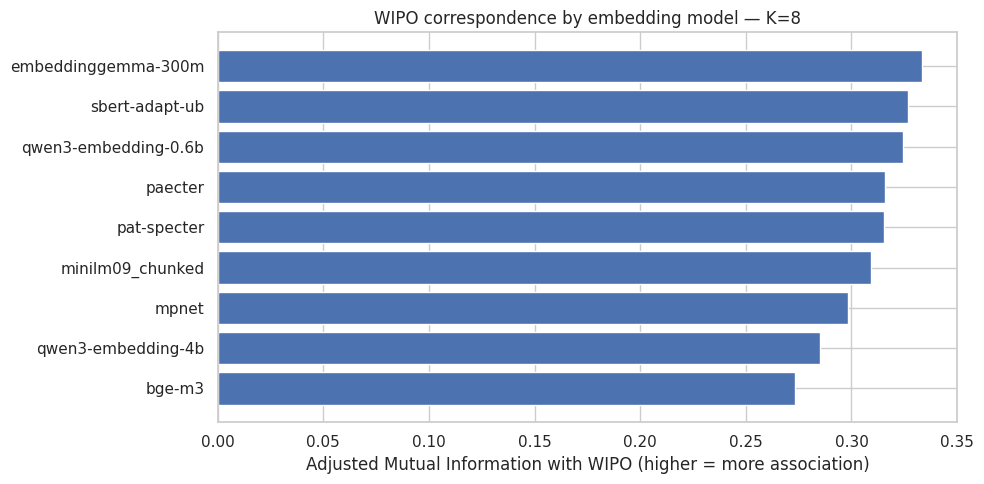

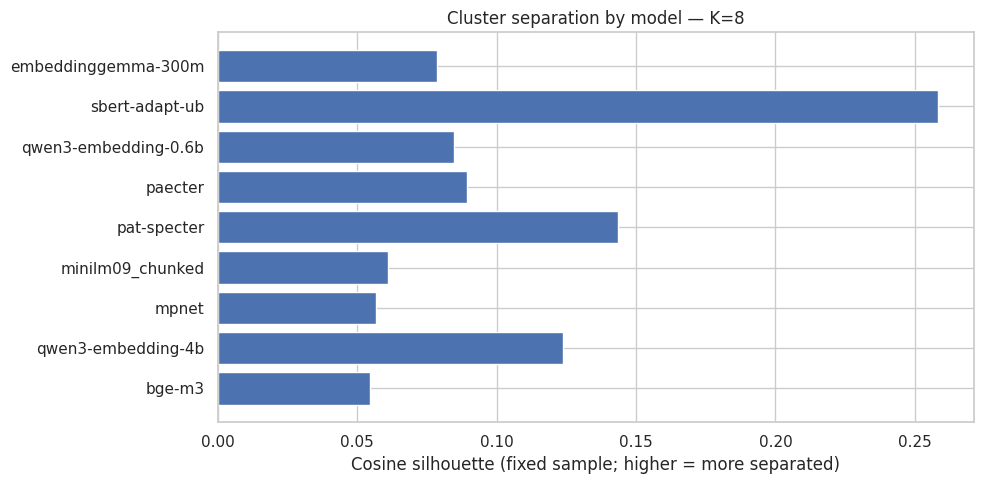

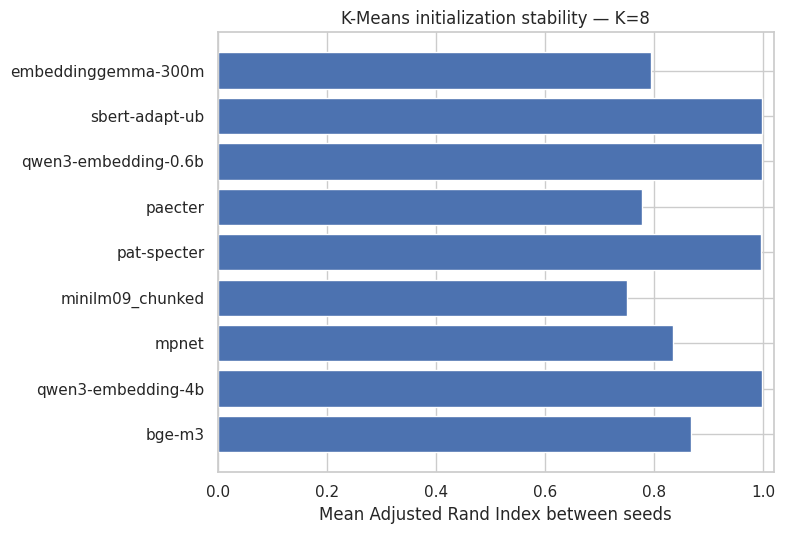

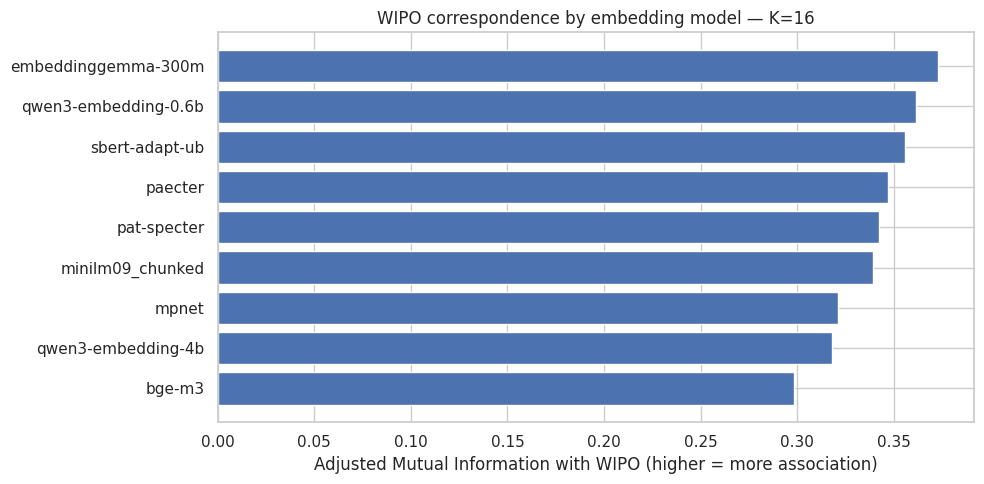

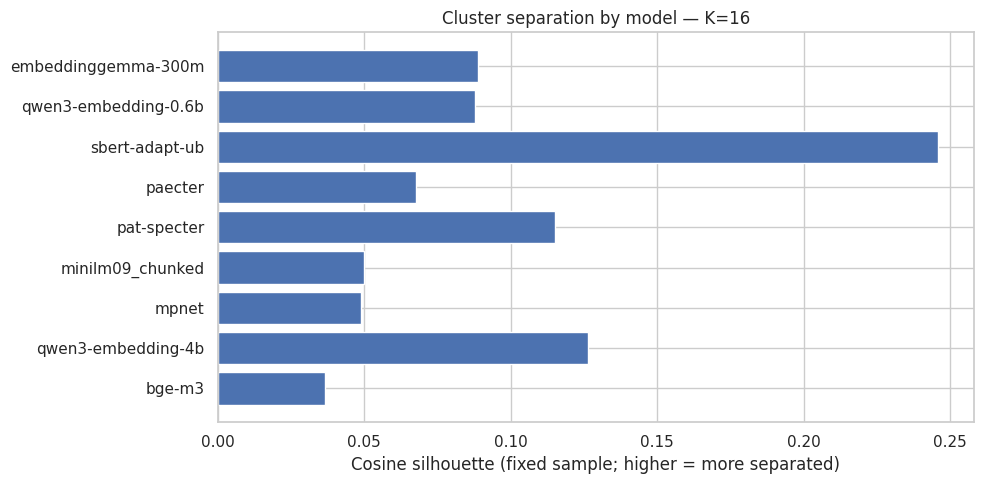

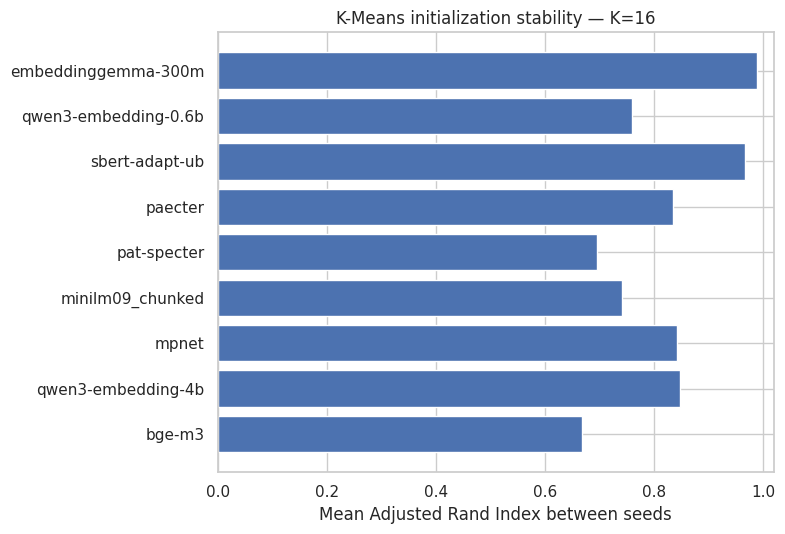

In [ ]:
# Model names may be long. Keep figure labels readable.
sns.set_theme(style='whitegrid', context='notebook')
for k in K_VALUES:
    view = summary.loc[summary['k'] == k].sort_values('WIPO_AMI_mean')
    if view.empty:
        continue
    fig, ax = plt.subplots(figsize=(10, max(5, len(view)*0.42)))
    ax.barh(view['model'], view['WIPO_AMI_mean'])
    ax.set(xlabel='Adjusted Mutual Information with WIPO (higher = more association)',
           title=f'WIPO correspondence by embedding model — K={k}')
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'figures' / f'13_WIPO_AMI_K{k}.png', dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(10, max(5, len(view)*0.42)))
    ax.barh(view['model'], view['silhouette_mean'])
    ax.set(xlabel='Cosine silhouette (fixed sample; higher = more separated)',
           title=f'Cluster separation by model — K={k}')
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'figures' / f'13_cosine_silhouette_K{k}.png', dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 5.5))
    scatter = view.dropna(subset=['seed_ARI_mean'])
    ax.barh(scatter['model'], scatter['seed_ARI_mean'])
    ax.set(xlim=(0,1.02), xlabel='Mean Adjusted Rand Index between seeds',
           title=f'K-Means initialization stability — K={k}')
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'figures' / f'13_seed_stability_K{k}.png', dpi=180)
    plt.show()

## 9. Do different models assign the same patents to similar groups?

Compute **cross-model ARI** on the same patent cohort using the first seed at each K. ARI does not require matching numeric cluster IDs. This comparison is valuable even when the models have different embedding dimensions.

A high pairwise ARI does not prove either model is correct; it means they find similar partitions.

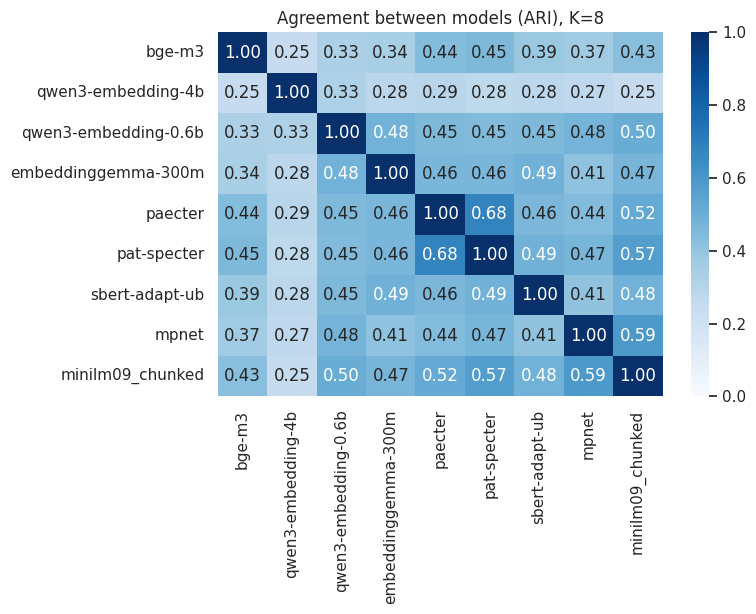

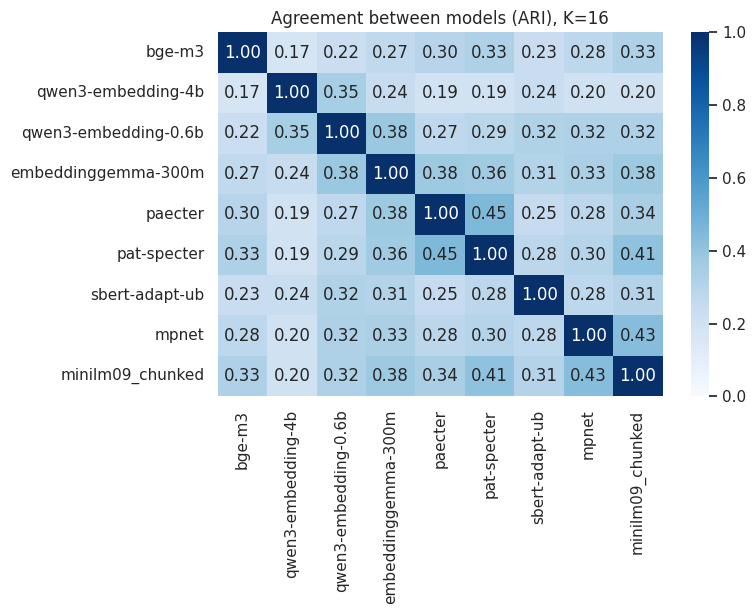

In [ ]:
# Compare the first-seed partition of each model. All have identical ordered publication IDs.
for k in K_VALUES:
    ref_labels = {}
    for model_name in model_names:
        path = OUT_DIR / 'labels' / f'{model_name}__k{k}__reference_assignments.parquet'
        frame = pd.read_parquet(path, columns=['publication_number','cluster'])
        assert frame['publication_number'].astype('string').tolist() == cohort['publication_number'].tolist()
        ref_labels[model_name] = frame['cluster'].to_numpy(dtype=int)
    cross = pd.DataFrame(index=model_names, columns=model_names, dtype=float)
    for a in model_names:
        for b in model_names:
            cross.loc[a,b] = adjusted_rand_score(ref_labels[a], ref_labels[b])
    cross.to_csv(OUT_DIR / f'13_cross_model_ARI_K{k}.csv')
    fig, ax = plt.subplots(figsize=(max(8, len(model_names)*0.85), max(6, len(model_names)*0.7)))
    sns.heatmap(cross, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax)
    ax.set_title(f'Agreement between models (ARI), K={k}')
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'figures' / f'13_cross_model_ARI_K{k}.png', dpi=180)
    plt.show()

## 10. WIPO heatmaps and cluster-size profiles

For each representation, export a WIPO-field × cluster matrix. **Rows are normalized**, so each row shows where patents *from one WIPO reference field* end up.

Cluster labels are arbitrary across models. Inspect these tables independently; use the ARI heatmap to compare partitions across models.

In [ ]:
# Generate field-normalized matrices for every model and K; figures only for K=8.
cluster_size_rows = []
for model_name in model_names:
    for k in K_VALUES:
        fname = OUT_DIR / 'labels' / f'{model_name}__k{k}__reference_assignments.parquet'
        part = pd.read_parquet(fname)
        matrix = pd.crosstab(part['field_label'], part['cluster'], normalize='index')
        matrix = matrix.reindex(columns=list(range(k)), fill_value=0)
        matrix.to_csv(OUT_DIR / f'13_WIPO_by_cluster_{model_name}_K{k}.csv')
        sizes = part['cluster'].value_counts().sort_index()
        for cluster, n in sizes.items():
            cluster_size_rows.append(dict(model=model_name, k=k, cluster=int(cluster),
                                          n=int(n), share=float(n/len(part))))
        if k == 8:
            fig, ax = plt.subplots(figsize=(10, 11))
            sns.heatmap(matrix, cmap='Blues', vmin=0, vmax=1, ax=ax,
                        cbar_kws={'label': 'Share within WIPO field'})
            ax.set(xlabel='Semantic cluster (numeric label is arbitrary)',
                   ylabel='WIPO reference field',
                   title=f'WIPO vs. semantic clusters — {model_name} (K={k})')
            fig.tight_layout()
            fig.savefig(OUT_DIR / 'figures' / f'13_WIPO_heatmap_{model_name}_K{k}.png', dpi=160)
            plt.close(fig)

pd.DataFrame(cluster_size_rows).to_csv(OUT_DIR / '13_cluster_sizes.csv', index=False)
print('Saved row-normalized WIPO matrices for every model and K.')
print('Saved K=8 heatmaps (8 HF models plus MiniLM if available).')

Saved row-normalized WIPO matrices for every model and K.
Saved K=8 heatmaps (8 HF models plus MiniLM if available).


## 11. Prepare human-review examples: central, peripheral and boundary patents

A model can get good metrics while grouping patents that **do not share a coherent technological theme**. We therefore export candidates for manual review:

- 5 **central** patents per cluster (closest to K-Means center),
- 5 **peripheral** patents (farthest from their assigned center),
- 5 **boundary** patents (smallest gap between their two closest centers).

These categories are based on **Euclidean distances used by K-Means**; they are diagnostic samples, not automatically correct labels. The exported text is included if Notebook 12's master retained `title_clean`/`abstract_clean`.

In [ ]:
# Default to a small list of promising/interesting models rather than reloading all 9.
# To review every model, set REVIEW_MODELS = model_names.
# REVIEW_MODELS = [m for m in ['minilm09_chunked', 'sbert-adapt-ub', 'paecter', 'qwen3-embedding-4b']
#                  if m in model_names]
REVIEW_MODELS = model_names

REVIEW_K = 8

review_rows = []
for model_name in REVIEW_MODELS:
    X = load_minilm09_matrix() if model_name == 'minilm09_chunked' else load_hf_matrix(model_name)
    km, labels, _, _ = get_or_fit_kmeans(model_name, X, REVIEW_K, SEEDS[0])
    with threadpool_limits(limits=THREADS):
        distance_to_centers = km.transform(X)
    for cluster in range(REVIEW_K):
        members = np.flatnonzero(labels == cluster)
        assigned_distance = distance_to_centers[members, cluster]
        # Smaller = nearer center; larger = peripheral.
        most_central = members[np.argsort(assigned_distance)[:REVIEW_PER_TYPE_PER_CLUSTER]]
        peripheral = members[np.argsort(assigned_distance)[-REVIEW_PER_TYPE_PER_CLUSTER:]]
        # For boundary points, compare the two nearest centroid distances.
        nearest_two = np.partition(distance_to_centers[members], 1, axis=1)[:, :2]
        margin = nearest_two[:,1] - nearest_two[:,0]
        boundary = members[np.argsort(margin)[:REVIEW_PER_TYPE_PER_CLUSTER]]
        for kind, chosen in [('central', most_central), ('peripheral', peripheral),
                             ('boundary', boundary)]:
            for i in chosen:
                row = dict(model=model_name, k=REVIEW_K, cluster=cluster,
                           selection_type=kind,
                           dist_assigned_centroid=float(distance_to_centers[i,cluster]),
                           nearest_two_centroid_gap=float(
                               np.partition(distance_to_centers[i], 1)[:2][1] -
                               np.partition(distance_to_centers[i], 1)[:2][0]))
                row.update(cohort.iloc[int(i)][[c for c in
                    ['publication_number','wipo_field_number','wipo_field_name','office',
                     'title_clean','abstract_clean'] if c in cohort.columns]].to_dict())
                review_rows.append(row)
    del X, km, labels, distance_to_centers
    gc.collect()

review_df = pd.DataFrame(review_rows)
review_df.to_csv(OUT_DIR / '13_patents_for_manual_review.csv', index=False)
print('Exported review candidates:', len(review_df))
display(review_df.head(8))

bge-m3                   : X=(63968, 1024), float32, max L2 error before renormalization=0.00007
qwen3-embedding-4b       : X=(63968, 2560), float32, max L2 error before renormalization=0.00390
qwen3-embedding-0.6b     : X=(63968, 1024), float32, max L2 error before renormalization=0.00386
embeddinggemma-300m      : X=(63968, 768), float32, max L2 error before renormalization=0.00391
paecter                  : X=(63968, 1024), float32, max L2 error before renormalization=0.00006
pat-specter              : X=(63968, 768), float32, max L2 error before renormalization=0.00014
sbert-adapt-ub           : X=(63968, 384), float32, max L2 error before renormalization=0.00009
mpnet                    : X=(63968, 768), float32, max L2 error before renormalization=0.00007
minilm09_chunked         : X=(63968, 384), float32, max L2 error before renormalization=0.00000
Exported review candidates: 1080


,model,k,cluster,selection_type,dist_assigned_centroid,nearest_two_centroid_gap,publication_number,wipo_field_number,wipo_field_name,office,title_clean,abstract_clean
0,bge-m3,8,0,central,0.596220,0.086648,CN-116234810-B,16,Pharmaceuticals,CN,Cell apoptosis inhibitor and preparation metho...,The invention provides a cell apoptosis inhibi...
1,bge-m3,8,0,central,0.612661,0.050493,CN-121270563-A,16,Pharmaceuticals,CN,"Condensed-cyclic compound, preparation method ...",The invention relates to a fused ring compound...
2,bge-m3,8,0,central,0.614184,0.124142,CN-113226323-B,14,Organic fine chemistry,CN,"Ma Dexin derivative compounds, compositions an...",The present invention relates to the field of ...
3,bge-m3,8,0,central,0.614628,0.113691,EP-4353258-A1,15,Biotechnology,EP,Pharmaceutical composition for preventing or t...,An object of the present invention is to revea...
4,bge-m3,8,0,central,0.616610,0.101387,CA-3043549-C,14,Organic fine chemistry,CA,Compounds for treating proliferative diseases,The present disclosure provides compounds of F...
5,bge-m3,8,0,peripheral,0.868273,0.025050,US-PP33234-P2,18,Food chemistry,US,Baptisia plant named ‘Blue Bubbly’,A new and distinct plant cultivar of hardy her...
6,bge-m3,8,0,peripheral,0.869516,0.032623,US-PP35353-P2,18,Food chemistry,US,Styrax plant ‘RNI-Rixred’,A new and distinct cultivar of Styrax plant na...
7,bge-m3,8,0,peripheral,0.881863,0.039012,US-PP36202-P2,18,Food chemistry,US,Petunia plant named ‘PEHY0085’,A new Petunia plant named ‘PEHY0085’ particula...


## 12. Concise research report and output checklist

The generated report is deliberately cautious: **WIPO is not a gold standard**, high-dimensional silhouette values should not be used in isolation, and the original MiniLM preprocessing differs from Mauro's no-chunking pipeline.

In [ ]:
# Write a short Markdown report that can be pasted into the research document.
lines = [
    '# Notebook 13 — Multi-model patent K-Means benchmark', '',
    f'- Dataset: `{HF_REPO}`, commit `{HF_REVISION}`.',
    f'- Cohort: **{N:,} patents** across 32 WIPO fields.',
    f'- Repeated clustering: K={K_VALUES}, seeds={SEEDS}, n_init={N_INIT}.',
    f'- Fixed cosine silhouette evaluation sample: **{len(sil_pos):,}** patents.',
    f'- Models actually compared: {", ".join(model_names)}.',
    '- All matrices are checked for finite/nonzero values and L2-renormalized.',
    '- WIPO uses the deterministic Notebook 09 single-field convention; multi-field nature remains.',
    '- Mauro HF embeddings: no chunking; native token limits and prefixes vary.',
    '- Historical MiniLM09: overlapping chunk mean; its scores are remeasured on this cohort.',
    '', '## Measured results', '',
    summary[['model','k','n_seeds','silhouette_mean','WIPO_AMI_mean',
             'office_AMI_mean','seed_ARI_mean','largest_cluster_share_mean']]
        .round(4).to_markdown(index=False),
    '', '## Interpretation constraints', '',
    '- No benchmark metric alone proves semantic heterogeneity.',
    '- A higher WIPO AMI is stronger correspondence to the selected WIPO label, not classification accuracy.',
    '- Silhouette values from different embedding spaces reflect different geometries.',
    '- Investigate model-to-model ARI, cluster balance and the manual-review examples.',
    '- The full sample is WIPO-stratified and heavily CN-skewed; office associations matter.',
    '- To conclude that the new corpus is MORE heterogeneous than the OLD sample, compare both samples directly.',
    '', '## Recommended next analysis', '',
    'Select two or three complementary embedding representations based on several metrics.',
    'Then benchmark spherical K-Means and HDBSCAN (Notebook 14), and manually validate clusters.',
]
report_path = OUT_DIR / '13_multimodel_benchmark_report.md'
report_path.write_text('\n'.join(lines), encoding='utf-8')

print('Completed Notebook 13. Saved to:', OUT_DIR)
for name in ['13_model_K_summary.csv','13_seed_metrics.csv','13_seed_stability_ARI.csv',
             '13_cross_model_ARI_K8.csv','13_patents_for_manual_review.csv',
             '13_multimodel_benchmark_report.md']:
    path = OUT_DIR/name
    print(' -', name, 'OK' if path.exists() else 'MISSING')

Completed Notebook 13. Saved to: /content/drive/MyDrive/istat_patents/semantic_results_v10_multimodel_kmeans/full/all_texts
 - 13_model_K_summary.csv OK
 - 13_seed_metrics.csv OK
 - 13_seed_stability_ARI.csv OK
 - 13_cross_model_ARI_K8.csv OK
 - 13_patents_for_manual_review.csv OK
 - 13_multimodel_benchmark_report.md OK


## 13. What to send back for interpretation

At minimum, share these small files from your `semantic_results_v10_multimodel_kmeans/...` folder:

1. `13_model_K_summary.csv` — **main comparison**.
2. `13_seed_stability_ARI.csv` — replicate stability by K and seed.
3. `13_cross_model_ARI_K8.csv` (and K16) — how similar the discovered partitions are.
4. `13_cluster_sizes.csv` — large/small clusters.
5. `13_multimodel_benchmark_report.md` — research summary.
6. Optionally `13_patents_for_manual_review.csv` — sample titles/abstracts for checking labels.

**Do not call a single model the winner based solely on AMI or silhouette.** We will next decide which models deserve alternative clustering (Notebook 14), and whether the corpus exhibits *meaningful* semantic heterogeneity.

**Suggested sequence:** pilot first → interpret model and K effects → optional five-seed/full-corpus replication → alternative cluster algorithms → human semantic review and old-vs-new sample comparison.